<a href="https://colab.research.google.com/github/minhphu12-oc/gg-colab/blob/sklearn-project-for-machine-learning/project_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

link dataset : https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

# Bước 1: đọc dữ liệu

1.1 tải dữ liệu lên và đọc 5 dòng đầu

In [5]:
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks, RandomUnderSampler
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
import zipfile
import pandas as pd
# giải nén file
zip_path = '/content/statlog+german+credit+data.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/german_credit')
# tải dữ liệu lên
df = pd.read_csv('/content/german_credit/german.data', header=None, sep='\s+')

<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1897/3689707072.py:8: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv('/content/german_credit/german.data', header=None, sep='\s+')


In [7]:
df.rename(columns={20: 'Creditability'}, inplace=True)
df["Creditability"] = df["Creditability"].map({1: 0, 2: 1})

In [8]:
df.head(5)

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,Creditability
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


1.2 đọc thông tin dữ liệu

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   0              1000 non-null   object
 1   1              1000 non-null   int64 
 2   2              1000 non-null   object
 3   3              1000 non-null   object
 4   4              1000 non-null   int64 
 5   5              1000 non-null   object
 6   6              1000 non-null   object
 7   7              1000 non-null   int64 
 8   8              1000 non-null   object
 9   9              1000 non-null   object
 10  10             1000 non-null   int64 
 11  11             1000 non-null   object
 12  12             1000 non-null   int64 
 13  13             1000 non-null   object
 14  14             1000 non-null   object
 15  15             1000 non-null   int64 
 16  16             1000 non-null   object
 17  17             1000 non-null   int64 
 18  18             1000 non-null 

1.3 xem dữ liệu có bị thiếu không

In [10]:
df.isnull().sum().sum()

np.int64(0)

bài toán yêu cầu phải phân loại giữa 0 và 1 ( 0: tốt , 1: xấu ) nên ta sẽ chọn các model phân loại phù hợp
1. LogisticRegression
2. SVM
3. RandomForest
4. DecisionTree
5. KNN

# Bước 2: xử lí dữ liệu

2.1 tách dữ liệu

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [12]:
x = df.drop('Creditability', axis=1)
y = df['Creditability']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [13]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(800, 20)
(800,)
(200, 20)
(200,)


In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(x_train, y_train)
dummy.score(x_test, y_test)
f1 = f1_score(y_test, dummy.predict(x_test))
acc = accuracy_score(y_test, dummy.predict(x_test))
pre = precision_score(y_test, dummy.predict(x_test))
rec = recall_score(y_test, dummy.predict(x_test))
table = pd.DataFrame({
    "Model": ["Dummy"],
    "Accuracy": [acc],
    "Precision": [pre],
    "Recall": [rec],
    "F1-Score": [f1]
})
table.set_index("Model", inplace=True)
display(table.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Dummy,0.700000,0.000000,0.000000,0.000000


2.2 chuẩn hoá dữ liệu

In [15]:
from sklearn.preprocessing import PowerTransformer

model = {"Logis" : LogisticRegression(),
         "Random" : RandomForestClassifier(random_state=42),
         "Tree" : DecisionTreeClassifier(random_state=42),
         "KNN" : KNeighborsClassifier(),
         "SVM" : SVC()}

numerical_cols = x.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = x.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer([("scaler", PowerTransformer(method='yeo-johnson'), numerical_cols),
                                  ("encoder", OneHotEncoder(handle_unknown='ignore'), categorical_cols)])

2.3 train model cơ bản

In [16]:
results = []

for name, clf in model.items():
  pipe = Pipeline([("preprocessor", preprocessor),
                  ("model", clf)])
  pipe.fit(x_train, y_train)
  y_pred = pipe.predict(x_test)

  acc = accuracy_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  pre = precision_score(y_test, y_pred)
  rec = recall_score(y_test, y_pred)

  results.append({
      "Model": name,
      "Accuracy": acc,
      "Precision": pre,
      "Recall": rec,
      "F1-Score": f1
  })

table1 = pd.DataFrame(results)
table1.reset_index(drop=True, inplace=True)
table1.set_index("Model", inplace=True)
display(table1.style.highlight_max(axis=0, color='green', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logis,0.765000,0.632653,0.516667,0.568807
Random,0.735000,0.589744,0.383333,0.464646
Tree,0.635000,0.385965,0.366667,0.376068
KNN,0.730000,0.575000,0.383333,0.460000
SVM,0.755000,0.641026,0.416667,0.505051


2.4 tuning

2.4.1 LOGISTIC REGRESSION

In [17]:
st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))])

param_grid_log = {
    "model__C": np.linspace(0.001, 1.0, 1000).tolist(),
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear", "saga"],
    "model__class_weight": [None, "balanced"]}

grid_log = RandomizedSearchCV(model_pipeline, param_grid_log, cv=st, scoring="f1", n_jobs=-1, n_iter=100, random_state=42)
grid_log.fit(x_train, y_train)
prediction = grid_log.predict(x_test)

acc = accuracy_score(y_test, prediction)
f1 = f1_score(y_test, prediction)
pre = precision_score(y_test, prediction)
rec = recall_score(y_test, prediction)

table = pd.DataFrame({
    "Model": ["LogisticRegression"],
    "Accuracy": [acc],
    "Precision": [pre],
    "Recall": [rec],
    "F1-Score": [f1]
})
table.set_index("Model", inplace=True)
display(table.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_log.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
LogisticRegression,0.715000,0.516854,0.766667,0.617450


Best param : {'model__solver': 'liblinear', 'model__penalty': 'l1', 'model__class_weight': 'balanced', 'model__C': 0.34400000000000003}


2.4.2 RANDOMFOREST

In [18]:
pipe = Pipeline([("preprocessor", preprocessor),
                ("model", RandomForestClassifier(random_state=42))])

param_grid_rf = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [None, "balanced", "balanced_subsample"]
}
grid_rf = RandomizedSearchCV(pipe, param_grid_rf, cv=st, scoring="f1", n_jobs=-1, n_iter=100, random_state=42)
grid_rf.fit(x_train, y_train)
y_pred = grid_rf.predict(x_test)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

table = pd.DataFrame({
    "Model": ["RandomForest"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]})
table.set_index("Model", inplace=True)
display(table.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_rf.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
RandomForest,0.745000,0.563380,0.666667,0.610687


Best param : {'model__n_estimators': 100, 'model__min_samples_split': 20, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 15, 'model__class_weight': 'balanced'}


2.4.3 Decisiontree

In [19]:
pipe = Pipeline([("preprocessor", preprocessor),
                ("model", DecisionTreeClassifier(random_state=42))])

param_grid_tree = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__splitter": ["best", "random"],
    "model__max_depth": [None, 5, 10, 15, 20, 30],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": [None, "sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}
grid_tree = RandomizedSearchCV(pipe, param_grid_tree, cv = st, n_jobs = -1, n_iter = 50, random_state = 42)
grid_tree.fit(x_train, y_train)
predict = grid_tree.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)
table = pd.DataFrame({
    "Model": ["DecisionTree"],
    "Accuracy": [acc],
    "Precision": [pre],
    "Recall": [rec],
    "F1-Score": [f1]
})
table.set_index("Model", inplace=True)
display(table.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_log.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
DecisionTree,0.660000,0.516854,0.766667,0.460317


Best param : {'model__solver': 'liblinear', 'model__penalty': 'l1', 'model__class_weight': 'balanced', 'model__C': 0.34400000000000003}


2.4.4 KNN

In [20]:
pipe = Pipeline([("preprocessor", preprocessor),
                ("model", KNeighborsClassifier())])

param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 20],
    "model__weights": ["uniform", "distance"],
    "model__algorithm": ["auto", "ball_tree", "kd_tree", "brute"],
    "model__leaf_size": [20, 30, 40, 50],
    "model__p": [1, 2],
    "model__metric": ["minkowski", "manhattan", "euclidean"]
}
grid_knn = RandomizedSearchCV(pipe, param_grid_knn, cv = st, n_jobs = -1, n_iter = 100, random_state = 42)
grid_knn.fit(x_train, y_train)
predict = grid_knn.predict(x_test)
acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)
table = pd.DataFrame({
    "Model": ["KNN"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]})
table.set_index("Model", inplace=True)
display(table.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_knn.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
KNN,0.710000,0.527778,0.316667,0.395833


Best param : {'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 7, 'model__metric': 'minkowski', 'model__leaf_size': 50, 'model__algorithm': 'auto'}


2.4.5 SVM

In [21]:
pipe = Pipeline([("preprocessor", preprocessor),
                ("model", SVC())])
param_grid_svc = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf", "poly", "sigmoid"],
    "model__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
    "model__degree": [2, 3, 4, 5],
    "model__class_weight": [None, "balanced"],
    "model__probability": [True]
}
grid_svm = RandomizedSearchCV(pipe, param_grid_svc, cv = st, n_jobs = -1, n_iter = 50, random_state = 42)
grid_svm.fit(x_train, y_train)
predict = grid_svm.predict(x_test)
acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)
table = pd.DataFrame({
    "Model": ["SVM"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]})
table.set_index("Model", inplace=True)
display(table.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"best param: {grid_svm.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
SVM,0.765000,0.632653,0.516667,0.568807


best param: {'model__probability': True, 'model__kernel': 'linear', 'model__gamma': 0.001, 'model__degree': 5, 'model__class_weight': None, 'model__C': 1}


ta thấy hầu hết điểm đều giảm so với model cơ bản. nguyên nhân là do data imbalance dẫn đến các chỉ số kéo mạnh về phía majority nên gây ra chênh lệch giảm hiệu suất dự đoán của máy

2.5 SMOTE

/tmp/ipykernel_1897/103792419.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], x='Creditability', y='Count', data=y_train_before, palette='Blues_r')
/tmp/ipykernel_1897/103792419.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x='Creditability', y='Count', data=y_train_after, palette='Oranges_r')


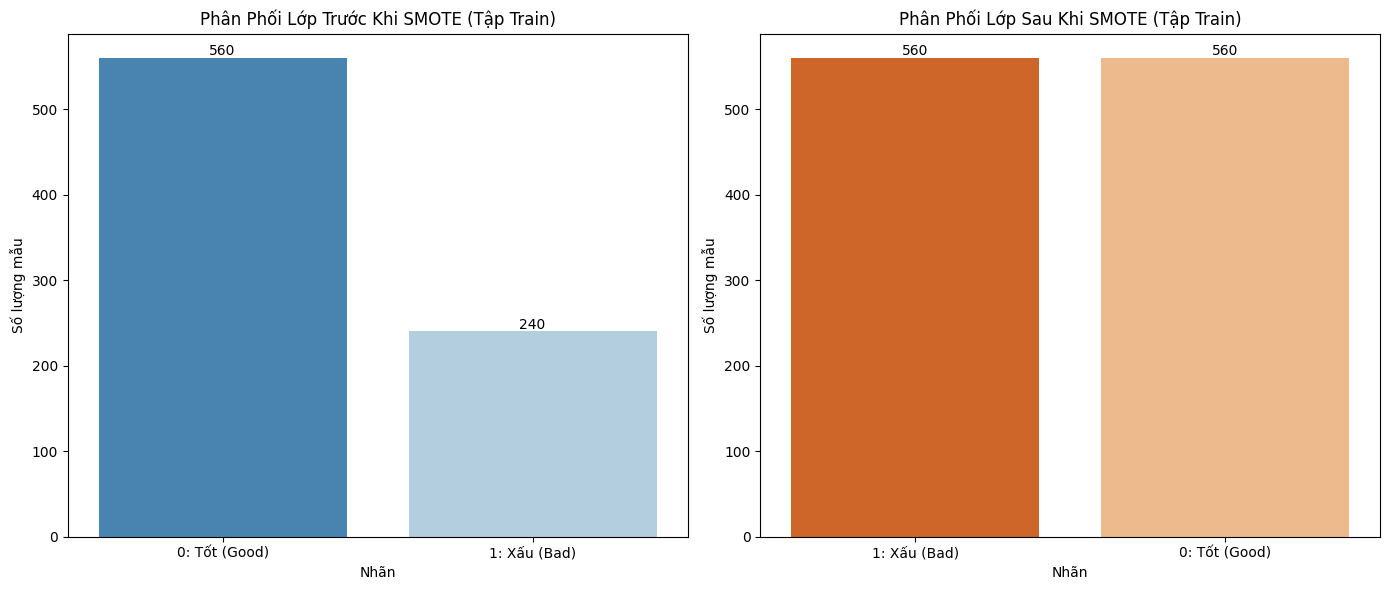

In [22]:
# 1. Trước khi áp dụng SMOTE
y_train_before = y_train.value_counts().reset_index()
y_train_before.columns = ['Creditability', 'Count']
y_train_before['Creditability'] = y_train_before['Creditability'].map({0: '0: Tốt (Good)', 1: '1: Xấu (Bad)'})

# 2. Thực hiện SMOTE trên tập huấn luyện thực tế để lấy dữ liệu vẽ biểu đồ
smote_instance = SMOTE(random_state=42)
# Vì SMOTE cần dữ liệu đầu vào đã được mã hóa/chuẩn hóa, ta áp dụng preprocessor trước
x_train_preprocessed = preprocessor.fit_transform(x_train)
x_train_res, y_train_res = smote_instance.fit_resample(x_train_preprocessed, y_train)

y_train_after = pd.Series(y_train_res).value_counts().reset_index()
y_train_after.columns = ['Creditability', 'Count']
y_train_after['Creditability'] = y_train_after['Creditability'].map({0: '0: Tốt (Good)', 1: '1: Xấu (Bad)'})

# 3. Vẽ biểu đồ so sánh song song
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Biểu đồ trước SMOTE
sns.barplot(ax=axes[0], x='Creditability', y='Count', data=y_train_before, palette='Blues_r')
axes[0].set_title('Phân Phối Lớp Trước Khi SMOTE (Tập Train)')
axes[0].set_xlabel('Nhãn')
axes[0].set_ylabel('Số lượng mẫu')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Biểu đồ sau SMOTE
sns.barplot(ax=axes[1], x='Creditability', y='Count', data=y_train_after, palette='Oranges_r')
axes[1].set_title('Phân Phối Lớp Sau Khi SMOTE (Tập Train)')
axes[1].set_xlabel('Nhãn')
axes[1].set_ylabel('Số lượng mẫu')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

2.5.1 logisticregression

In [23]:
from imblearn.pipeline import Pipeline as ImbPipeline

pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid_log = {
    "smote__sampling_strategy": ["minority", "not majority"],
    "smote__k_neighbors": [3, 5, 7],
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear", "saga"],
    "model__class_weight": [None, "balanced"]
}

grid_log_smote = RandomizedSearchCV(pipe, param_grid_log, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_log_smote.fit(x_train, y_train)
predict = grid_log_smote.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_log_smote = pd.DataFrame({
    "Model": ["LogisticRegression (SMOTE)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_log_smote.set_index("Model", inplace=True)
display(table_log_smote.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_log_smote.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
LogisticRegression (SMOTE),0.715000,0.517647,0.733333,0.606897


Best param : {'smote__sampling_strategy': 'not majority', 'smote__k_neighbors': 5, 'model__solver': 'saga', 'model__penalty': 'l2', 'model__class_weight': 'balanced', 'model__C': 0.1}


2.5.2 randomforest

In [24]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    "smote__sampling_strategy": ["minority", "not majority"],
    "smote__k_neighbors": [3, 5, 7],
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}
grid_rf_smote = RandomizedSearchCV(pipe, param_grid_rf, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_rf_smote.fit(x_train, y_train)
predict = grid_rf_smote.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_rf_smote = pd.DataFrame({
    "Model": ["RandomForest (SMOTE)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_rf_smote.set_index("Model", inplace=True)
display(table_rf_smote.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_rf_smote.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
RandomForest (SMOTE),0.720000,0.530303,0.583333,0.555556


Best param : {'smote__sampling_strategy': 'minority', 'smote__k_neighbors': 5, 'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': 'log2', 'model__max_depth': 5, 'model__class_weight': None}


2.5.3 decisiontree

In [25]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", DecisionTreeClassifier(random_state=42))
])
param_grid_dt = {
    "smote__sampling_strategy": ["minority", "not majority"],
    "smote__k_neighbors": [3, 5, 7],
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__splitter": ["best", "random"],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": [None, "sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}
grid_dt_smote = RandomizedSearchCV(pipe, param_grid_dt, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_dt_smote.fit(x_train, y_train)
predict = grid_dt_smote.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_dt_smote = pd.DataFrame({
    "Model": ["DecisionTree (SMOTE)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_dt_smote.set_index("Model", inplace=True)
display(table_dt_smote.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_dt_smote.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
DecisionTree (SMOTE),0.610000,0.387500,0.516667,0.442857


Best param : {'smote__sampling_strategy': 'minority', 'smote__k_neighbors': 5, 'model__splitter': 'best', 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': None, 'model__max_depth': 5, 'model__criterion': 'entropy', 'model__class_weight': 'balanced'}


2.5.4 knn

In [26]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", KNeighborsClassifier())])
param_grid_knn = {
    "smote__sampling_strategy": ["minority", "not majority"],
    "smote__k_neighbors": [3, 5, 7],
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 20],
    "model__weights": ["uniform", "distance"],
    "model__algorithm": ["auto", "ball_tree", "kd_tree", "brute"],
    "model__p": [1, 2],
    "model__leaf_size": [20, 30, 40]}
grid_knn_smote = RandomizedSearchCV(pipe, param_grid_knn, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_knn_smote.fit(x_train, y_train)
predict = grid_knn_smote.predict(x_test)
acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)
table_knn_smote = pd.DataFrame({
    "Model": ["KNN (SMOTE)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_knn_smote.set_index("Model", inplace=True)
display(table_knn_smote.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_knn_smote.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
KNN (SMOTE),0.580000,0.394737,0.750000,0.517241


Best param : {'smote__sampling_strategy': 'not majority', 'smote__k_neighbors': 7, 'model__weights': 'uniform', 'model__p': 2, 'model__n_neighbors': 20, 'model__leaf_size': 40, 'model__algorithm': 'ball_tree'}


2.5.5 svm

In [27]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", SVC())
])
param_grid_svc = {
    "smote__sampling_strategy": ["minority", "not majority"],
    "smote__k_neighbors": [3, 5, 7],
    "model__C": [0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto", 0.01, 0.1, 1],
    "model__degree": [2, 3, 4],
    "model__class_weight": [None, "balanced"]
}
grid_svc_smote = RandomizedSearchCV(pipe, param_grid_svc, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_svc_smote.fit(x_train, y_train)
predict = grid_svc_smote.predict(x_test)
acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)
table_svc_smote = pd.DataFrame({
    "Model": ["SVM (SMOTE)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]})
table_svc_smote.set_index("Model", inplace=True)
display(table_svc_smote.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_svc_smote.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
SVM (SMOTE),0.755000,0.577465,0.683333,0.625954


Best param : {'smote__sampling_strategy': 'not majority', 'smote__k_neighbors': 5, 'model__kernel': 'poly', 'model__gamma': 'auto', 'model__degree': 2, 'model__class_weight': None, 'model__C': 10}


có vẻ như data đã cải thiện dần hơn so với tuning ở dạng data imbalance nhưng chỉ số vẫn đang hợi flop . giờ thử chuyển sang smotek xem liệu chỉ số có ổn định hơn không

2.6 SMOTEK

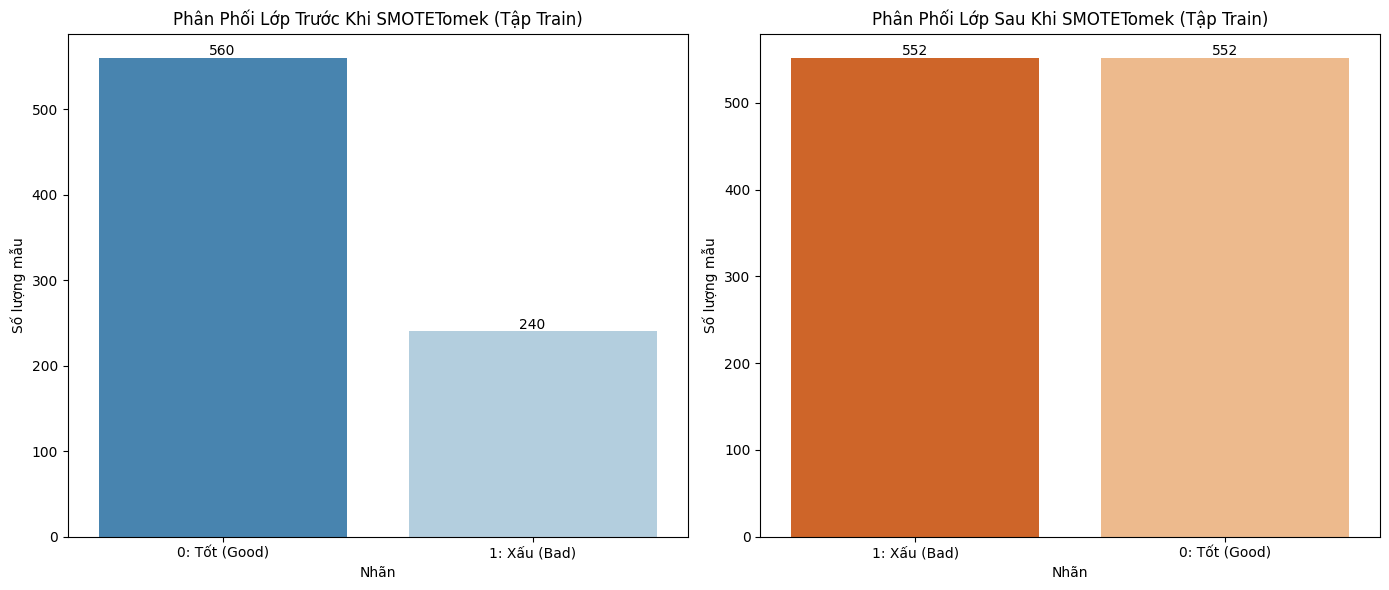

In [28]:
# 1. Trước khi áp dụng SMOTETomek
y_train_before = y_train.value_counts().reset_index()
y_train_before.columns = ['Creditability', 'Count']
y_train_before['Creditability'] = y_train_before['Creditability'].map({0: '0: Tốt (Good)', 1: '1: Xấu (Bad)'})

# 2. Thực hiện SMOTETomek trên tập huấn luyện thực tế để lấy dữ liệu vẽ biểu đồ
smotetomek_instance = SMOTETomek(random_state=42)
x_train_preprocessed = preprocessor.fit_transform(x_train)
x_train_res, y_train_res = smotetomek_instance.fit_resample(x_train_preprocessed, y_train)

y_train_after = pd.Series(y_train_res).value_counts().reset_index()
y_train_after.columns = ['Creditability', 'Count']
y_train_after['Creditability'] = y_train_after['Creditability'].map({0: '0: Tốt (Good)', 1: '1: Xấu (Bad)'})

# 3. Vẽ biểu đồ so sánh song song
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Biểu đồ trước SMOTETomek
sns.barplot(ax=axes[0], x='Creditability', y='Count', data=y_train_before, palette='Blues_r', hue='Creditability', legend=False)
axes[0].set_title('Phân Phối Lớp Trước Khi SMOTETomek (Tập Train)')
axes[0].set_xlabel('Nhãn')
axes[0].set_ylabel('Số lượng mẫu')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Biểu đồ sau SMOTETomek
sns.barplot(ax=axes[1], x='Creditability', y='Count', data=y_train_after, palette='Oranges_r', hue='Creditability', legend=False)
axes[1].set_title('Phân Phối Lớp Sau Khi SMOTETomek (Tập Train)')
axes[1].set_xlabel('Nhãn')
axes[1].set_ylabel('Số lượng mẫu')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()


2.6.1 logisticregression

In [29]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smotek", SMOTETomek(random_state=42)),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid_log = {
    "smotek__sampling_strategy": ["minority", "not majority"],
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear", "saga"],
    "model__class_weight": [None, "balanced"]
}

grid_log_smotek = RandomizedSearchCV(pipe, param_grid_log, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_log_smotek.fit(x_train, y_train)
predict = grid_log_smotek.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_log_smotek = pd.DataFrame({
    "Model": ["LogisticRegression (SMOTETomek)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_log_smotek.set_index("Model", inplace=True)
display(table_log_smotek.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_log_smotek.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
LogisticRegression (SMOTETomek),0.710000,0.511905,0.716667,0.597222


Best param : {'smotek__sampling_strategy': 'minority', 'model__solver': 'liblinear', 'model__penalty': 'l2', 'model__class_weight': 'balanced', 'model__C': 0.1}


2.6.2 randomforest

In [30]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smotek", SMOTETomek(random_state=42)),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    "smotek__sampling_strategy": ["minority", "not majority"],
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}

grid_rf_smotek = RandomizedSearchCV(pipe, param_grid_rf, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_rf_smotek.fit(x_train, y_train)
predict = grid_rf_smotek.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_rf_smotek = pd.DataFrame({
    "Model": ["RandomForest (SMOTETomek)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_rf_smotek.set_index("Model", inplace=True)
display(table_rf_smotek.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_rf_smotek.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
RandomForest (SMOTETomek),0.725000,0.542373,0.533333,0.537815


Best param : {'smotek__sampling_strategy': 'minority', 'model__n_estimators': 500, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 'log2', 'model__max_depth': 5, 'model__class_weight': None}


2.6.3 decisiontree

In [31]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smotek", SMOTETomek(random_state=42)),
    ("model", DecisionTreeClassifier(random_state=42))
])

param_grid_dt = {
    "smotek__sampling_strategy": ["minority", "not majority"],
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__splitter": ["best", "random"],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": [None, "sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}

grid_dt_smotek = RandomizedSearchCV(pipe, param_grid_dt, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_dt_smotek.fit(x_train, y_train)
predict = grid_dt_smotek.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_dt_smotek = pd.DataFrame({
    "Model": ["DecisionTree (SMOTETomek)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_dt_smotek.set_index("Model", inplace=True)
display(table_dt_smotek.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_dt_smotek.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
DecisionTree (SMOTETomek),0.610000,0.395349,0.566667,0.465753


Best param : {'smotek__sampling_strategy': 'minority', 'model__splitter': 'best', 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': None, 'model__max_depth': 5, 'model__criterion': 'gini', 'model__class_weight': 'balanced'}



2.6.4 knn

In [32]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smotek", SMOTETomek(random_state=42)),
    ("model", KNeighborsClassifier())
])

param_grid_knn = {
    "smotek__sampling_strategy": ["minority", "not majority"],
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 20],
    "model__weights": ["uniform", "distance"],
    "model__algorithm": ["auto", "ball_tree", "kd_tree", "brute"],
    "model__p": [1, 2],
    "model__leaf_size": [20, 30, 40]
}

grid_knn_smotek = RandomizedSearchCV(pipe, param_grid_knn, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_knn_smotek.fit(x_train, y_train)
predict = grid_knn_smotek.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_knn_smotek = pd.DataFrame({
    "Model": ["KNN (SMOTETomek)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_knn_smotek.set_index("Model", inplace=True)
display(table_knn_smotek.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_knn_smotek.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
KNN (SMOTETomek),0.720000,0.529412,0.600000,0.562500


Best param : {'smotek__sampling_strategy': 'not majority', 'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 20, 'model__leaf_size': 30, 'model__algorithm': 'ball_tree'}


2.6.5 svm

In [33]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smotek", SMOTETomek(random_state=42)),
    ("model", SVC())
])

param_grid_svc = {
    "smotek__sampling_strategy": ["minority", "not majority"],
    "model__C": [0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto", 0.01, 0.1, 1],
    "model__degree": [2, 3, 4],
    "model__class_weight": [None, "balanced"]
}

grid_svc_smotek = RandomizedSearchCV(pipe, param_grid_svc, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_svc_smotek.fit(x_train, y_train)
predict = grid_svc_smotek.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_svc_smotek = pd.DataFrame({
    "Model": ["SVM (SMOTETomek)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_svc_smotek.set_index("Model", inplace=True)
display(table_svc_smotek.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_svc_smotek.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
SVM (SMOTETomek),0.705000,0.505882,0.716667,0.593103


Best param : {'smotek__sampling_strategy': 'not majority', 'model__kernel': 'rbf', 'model__gamma': 'scale', 'model__degree': 4, 'model__class_weight': None, 'model__C': 0.1}


2.7 Tomek Links

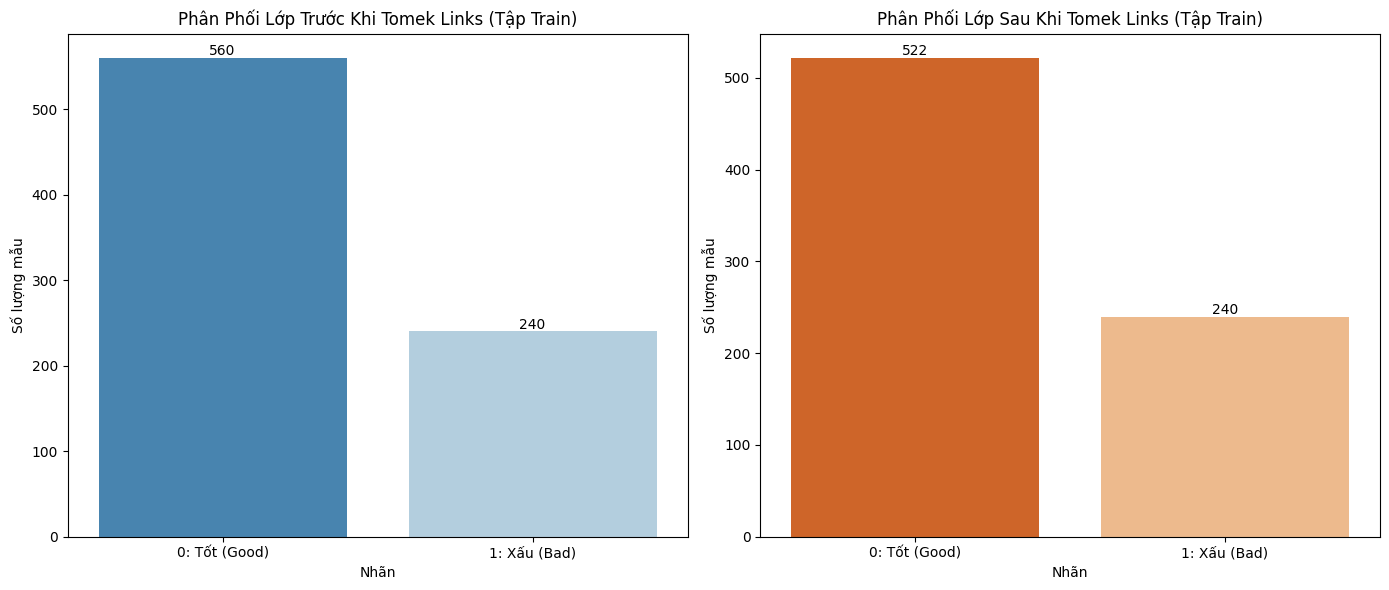

In [34]:
# 1. Trước khi áp dụng Tomek Links
y_train_before = y_train.value_counts().reset_index()
y_train_before.columns = ['Creditability', 'Count']
y_train_before['Creditability'] = y_train_before['Creditability'].map({0: '0: Tốt (Good)', 1: '1: Xấu (Bad)'})

# 2. Thực hiện Tomek Links trên tập huấn luyện thực tế để lấy dữ liệu vẽ biểu đồ
tomek_instance = TomekLinks()
x_train_preprocessed = preprocessor.fit_transform(x_train)
x_train_res, y_train_res = tomek_instance.fit_resample(x_train_preprocessed, y_train)

y_train_after = pd.Series(y_train_res).value_counts().reset_index()
y_train_after.columns = ['Creditability', 'Count']
y_train_after['Creditability'] = y_train_after['Creditability'].map({0: '0: Tốt (Good)', 1: '1: Xấu (Bad)'})

# 3. Vẽ biểu đồ so sánh song song
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Biểu đồ trước Tomek Links
sns.barplot(ax=axes[0], x='Creditability', y='Count', data=y_train_before, palette='Blues_r', hue='Creditability', legend=False)
axes[0].set_title('Phân Phối Lớp Trước Khi Tomek Links (Tập Train)')
axes[0].set_xlabel('Nhãn')
axes[0].set_ylabel('Số lượng mẫu')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Biểu đồ sau Tomek Links
sns.barplot(ax=axes[1], x='Creditability', y='Count', data=y_train_after, palette='Oranges_r', hue='Creditability', legend=False)
axes[1].set_title('Phân Phối Lớp Sau Khi Tomek Links (Tập Train)')
axes[1].set_xlabel('Nhãn')
axes[1].set_ylabel('Số lượng mẫu')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

2.7.1 logisticregression

In [35]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("tomek", TomekLinks()),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid_log = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear", "saga"],
    "model__class_weight": [None, "balanced"]
}

grid_log_tomek = RandomizedSearchCV(pipe, param_grid_log, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_log_tomek.fit(x_train, y_train)
predict = grid_log_tomek.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_log_tomek = pd.DataFrame({
    "Model": ["LogisticRegression (Tomek Links)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_log_tomek.set_index("Model", inplace=True)
display(table_log_tomek.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_log_tomek.best_params_}")

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 40 is smaller than n_iter=50. Running 40 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


,Accuracy,Precision,Recall,F1-Score
Model,,,,
LogisticRegression (Tomek Links),0.735000,0.539326,0.800000,0.644295


Best param : {'model__solver': 'saga', 'model__penalty': 'l2', 'model__class_weight': 'balanced', 'model__C': 0.1}


2.7.2 randomforest

In [36]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("tomek", TomekLinks()),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}

grid_rf_tomek = RandomizedSearchCV(pipe, param_grid_rf, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_rf_tomek.fit(x_train, y_train)
predict = grid_rf_tomek.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_rf_tomek = pd.DataFrame({
    "Model": ["RandomForest (Tomek Links)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_rf_tomek.set_index("Model", inplace=True)
display(table_rf_tomek.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_rf_tomek.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
RandomForest (Tomek Links),0.710000,0.511905,0.716667,0.597222


Best param : {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 'log2', 'model__max_depth': 5, 'model__class_weight': 'balanced'}



2.7.3 decisiontree

In [37]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("tomek", TomekLinks()),
    ("model", DecisionTreeClassifier(random_state=42))
])

param_grid_dt = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__splitter": ["best", "random"],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": [None, "sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}

grid_dt_tomek = RandomizedSearchCV(pipe, param_grid_dt, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_dt_tomek.fit(x_train, y_train)
predict = grid_dt_tomek.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_dt_tomek = pd.DataFrame({
    "Model": ["DecisionTree (Tomek Links)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_dt_tomek.set_index("Model", inplace=True)
display(table_dt_tomek.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_dt_tomek.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
DecisionTree (Tomek Links),0.685000,0.478261,0.550000,0.511628


Best param : {'model__splitter': 'random', 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': 'log2', 'model__max_depth': 15, 'model__criterion': 'log_loss', 'model__class_weight': 'balanced'}



2.7.4 knn

In [38]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("tomek", TomekLinks()),
    ("model", KNeighborsClassifier())
])

param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 20],
    "model__weights": ["uniform", "distance"],
    "model__algorithm": ["auto", "ball_tree", "kd_tree", "brute"],
    "model__p": [1, 2],
    "model__leaf_size": [20, 30, 40]
}

grid_knn_tomek = RandomizedSearchCV(pipe, param_grid_knn, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_knn_tomek.fit(x_train, y_train)
predict = grid_knn_tomek.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_knn_tomek = pd.DataFrame({
    "Model": ["KNN (Tomek Links)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_knn_tomek.set_index("Model", inplace=True)
display(table_knn_tomek.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"best param : {grid_knn_tomek.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
KNN (Tomek Links),0.735000,0.581395,0.416667,0.485437


best param : {'model__weights': 'distance', 'model__p': 2, 'model__n_neighbors': 5, 'model__leaf_size': 40, 'model__algorithm': 'auto'}


2.7.5 svm

In [39]:
pipe = ImbPipeline([
    ("preprocessor", preprocessor),
    ("tomek", TomekLinks()),
    ("model", SVC())
])

param_grid_svc = {
    "model__C": [0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto", 0.01, 0.1, 1],
    "model__degree": [2, 3, 4],
    "model__class_weight": [None, "balanced"]
}

grid_svc_tomek = RandomizedSearchCV(pipe, param_grid_svc, cv=st, scoring="f1", n_jobs=-1, n_iter=50, random_state=42)
grid_svc_tomek.fit(x_train, y_train)
predict = grid_svc_tomek.predict(x_test)

acc = accuracy_score(y_test, predict)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)

table_svc_tomek = pd.DataFrame({
    "Model": ["SVM (Tomek Links)"],
    "Accuracy": [acc],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1]
})
table_svc_tomek.set_index("Model", inplace=True)
display(table_svc_tomek.style.highlight_max(axis=0, color='gray', subset=["Accuracy", "Precision", "Recall", "F1-Score"]))
print(f"Best param : {grid_svc_tomek.best_params_}")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
SVM (Tomek Links),0.710000,0.511111,0.766667,0.613333


Best param : {'model__kernel': 'poly', 'model__gamma': 0.1, 'model__degree': 2, 'model__class_weight': 'balanced', 'model__C': 0.1}


# Bước 3: Lập bảng kết luận

In [40]:
summary_results = []

base_models_map = {"Logis": "LogisticRegression", "Random": "RandomForest", "Tree": "DecisionTree", "KNN": "KNN", "SVM": "SVM"}
for idx, row in table1.iterrows():
    full_name = base_models_map.get(idx, idx)
    summary_results.append({
        "Classifier": full_name,
        "Method": "Base Imbalance",
        "Accuracy": row["Accuracy"],
        "Precision": row["Precision"],
        "Recall": row["Recall"],
        "F1-Score": row["F1-Score"]
    })

smote_models = [
    ("LogisticRegression", table_log_smote),
    ("RandomForest", table_rf_smote),
    ("DecisionTree", table_dt_smote),
    ("KNN", table_knn_smote),
    ("SVM", table_svc_smote)
]
for class_name, tbl in smote_models:
    summary_results.append({
        "Classifier": class_name,
        "Method": "SMOTE",
        "Accuracy": tbl.iloc[0]["Accuracy"],
        "Precision": tbl.iloc[0]["Precision"],
        "Recall": tbl.iloc[0]["Recall"],
        "F1-Score": tbl.iloc[0]["F1-Score"]
    })

smotek_models = [
    ("LogisticRegression", table_log_smotek),
    ("RandomForest", table_rf_smotek),
    ("DecisionTree", table_dt_smotek),
    ("KNN", table_knn_smotek),
    ("SVM", table_svc_smotek)
]
for class_name, tbl in smotek_models:
    summary_results.append({
        "Classifier": class_name,
        "Method": "SMOTETomek",
        "Accuracy": tbl.iloc[0]["Accuracy"],
        "Precision": tbl.iloc[0]["Precision"],
        "Recall": tbl.iloc[0]["Recall"],
        "F1-Score": tbl.iloc[0]["F1-Score"]
    })

tomek_models = [
    ("LogisticRegression", table_log_tomek),
    ("RandomForest", table_rf_tomek),
    ("DecisionTree", table_dt_tomek),
    ("KNN", table_knn_tomek),
    ("SVM", table_svc_tomek)
]
for class_name, tbl in tomek_models:
    summary_results.append({
        "Classifier": class_name,
        "Method": "Tomek Links",
        "Accuracy": tbl.iloc[0]["Accuracy"],
        "Precision": tbl.iloc[0]["Precision"],
        "Recall": tbl.iloc[0]["Recall"],
        "F1-Score": tbl.iloc[0]["F1-Score"]
    })

compare_df = pd.DataFrame(summary_results)
compare_df = compare_df.sort_values(by=["Classifier", "Method"]).reset_index(drop=True)

def highlight_best_by_classifier(df):
    style_df = pd.DataFrame('', index=df.index, columns=df.columns)
    metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

    for clf in df["Classifier"].unique():
        clf_indices = df[df["Classifier"] == clf].index
        for metric in metrics:
            best_idx = df.loc[clf_indices, metric].idxmax()
            style_df.loc[best_idx, metric] = 'background-color: lightgreen; font-weight: bold'

    return style_df

compare_df.style.apply(highlight_best_by_classifier, axis=None)

,Classifier,Method,Accuracy,Precision,Recall,F1-Score
0,DecisionTree,Base Imbalance,0.635000,0.385965,0.366667,0.376068
1,DecisionTree,SMOTE,0.610000,0.387500,0.516667,0.442857
2,DecisionTree,SMOTETomek,0.610000,0.395349,0.566667,0.465753
3,DecisionTree,Tomek Links,0.685000,0.478261,0.550000,0.511628
4,KNN,Base Imbalance,0.730000,0.575000,0.383333,0.460000
5,KNN,SMOTE,0.580000,0.394737,0.750000,0.517241
6,KNN,SMOTETomek,0.720000,0.529412,0.600000,0.562500
7,KNN,Tomek Links,0.735000,0.581395,0.416667,0.485437
8,LogisticRegression,Base Imbalance,0.765000,0.632653,0.516667,0.568807
9,LogisticRegression,SMOTE,0.715000,0.517647,0.733333,0.606897


mặc dù có hai phương pháp có cải thiện đáng kể chỉ số f1 nhưng vẫn thọt khá nhiều

bổ sung

In [58]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV
acc = []
precision = []
recall = []
f1 = []
k = [5, 10, 15, 20]
for i in k:
  pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("select", SelectKBest(f_classif, k = i)),
    ("smotek", SMOTETomek(random_state=42)),
    ("model", LogisticRegression(max_iter=1000))])
  pipeline.fit(x_train, y_train)
  predict = pipeline.predict(x_test)
  acc.append(accuracy_score(y_test, predict))
  f1.append(f1_score(y_test, predict))
  precision.append(precision_score(y_test, predict))
  recall.append(recall_score(y_test, predict))

table_log_smotek_2 = pd.DataFrame({
    "k": k,
    "Accuracy": acc,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
})
table_log_smotek_2.set_index("k", inplace=True)
display(
    table_log_smotek_2.style.highlight_max(
        axis=0,
        color="green",
        subset=["Accuracy", "Precision", "Recall", "F1-Score"]))

,Accuracy,Precision,Recall,F1-Score
k,,,,
5,0.685000,0.482759,0.700000,0.571429
10,0.710000,0.511628,0.733333,0.602740
15,0.720000,0.525641,0.683333,0.594203
20,0.725000,0.533333,0.666667,0.592593


In [61]:
acc = []
precision = []
recall = []
f1 = []
k = [5, 10, 15, 20]
for i in k:
  pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("select", SelectKBest(f_classif, k = i)),
    ("smotek", SMOTETomek(random_state=42)),
    ("model", RandomForestClassifier(random_state=42, max_depth=6, max_leaf_nodes=5))])
  pipeline.fit(x_train, y_train)
  predict = pipeline.predict(x_test)
  acc.append(accuracy_score(y_test, predict))
  f1.append(f1_score(y_test, predict))
  precision.append(precision_score(y_test, predict))
  recall.append(recall_score(y_test, predict))

table_log_smotek_2 = pd.DataFrame({
    "k": k,
    "Accuracy": acc,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
})
table_log_smotek_2.set_index("k", inplace=True)
display(
    table_log_smotek_2.style.highlight_max(
        axis=0,
        color="green",
        subset=["Accuracy", "Precision", "Recall", "F1-Score"]))

,Accuracy,Precision,Recall,F1-Score
k,,,,
5,0.655000,0.454545,0.750000,0.566038
10,0.655000,0.452632,0.716667,0.554839
15,0.715000,0.516854,0.766667,0.617450
20,0.710000,0.511905,0.716667,0.597222
